# PlantCare-AI

## Data Preprocessing


In [4]:
from pathlib import Path

import os

import shutil

import random

from PIL import Image

import matplotlib.pyplot as plt

import pandas as pd

In [5]:
PROJECT_ROOT = Path("../")

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "PlantVillage"

PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed"

In [6]:
print(PROJECT_ROOT)

print(RAW_DATA_PATH)

print(PROCESSED_DATA_PATH)

..
..\data\raw\PlantVillage
..\data\processed


In [7]:
print(RAW_DATA_PATH.exists())

True


In [8]:
PROCESSED_DATA_PATH.mkdir(
    parents=True,
    exist_ok=True
)

In [9]:
print(PROCESSED_DATA_PATH.exists())

True


In [10]:
TRAIN_RATIO = 0.80
VAL_RATIO = 0.10
TEST_RATIO = 0.10

In [11]:
TRAIN_PATH = PROCESSED_DATA_PATH / "train"
VAL_PATH = PROCESSED_DATA_PATH / "validation"
TEST_PATH = PROCESSED_DATA_PATH / "test"

In [12]:
for folder in [TRAIN_PATH, VAL_PATH, TEST_PATH]:
    folder.mkdir(parents=True, exist_ok=True)

In [13]:
print(TRAIN_PATH.exists())
print(VAL_PATH.exists())
print(TEST_PATH.exists())

True
True
True


In [14]:
classes = sorted(
    [
        folder.name
        for folder in RAW_DATA_PATH.iterdir()
        if folder.is_dir()
    ]
)

print(f"Total Classes: {len(classes)}")

Total Classes: 38


In [15]:
for cls in classes:

    (TRAIN_PATH / cls).mkdir(exist_ok=True)

    (VAL_PATH / cls).mkdir(exist_ok=True)

    (TEST_PATH / cls).mkdir(exist_ok=True)

In [16]:
import math

In [17]:
for cls in classes:

    print(f"Processing: {cls}")

Processing: Apple___Apple_scab
Processing: Apple___Black_rot
Processing: Apple___Cedar_apple_rust
Processing: Apple___healthy
Processing: Blueberry___healthy
Processing: Cherry___Powdery_mildew
Processing: Cherry___healthy
Processing: Corn___Cercospora_leaf_spot Gray_leaf_spot
Processing: Corn___Common_rust
Processing: Corn___Northern_Leaf_Blight
Processing: Corn___healthy
Processing: Grape___Black_rot
Processing: Grape___Esca_(Black_Measles)
Processing: Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Processing: Grape___healthy
Processing: Orange___Haunglongbing_(Citrus_greening)
Processing: Peach___Bacterial_spot
Processing: Peach___healthy
Processing: Pepper,_bell___Bacterial_spot
Processing: Pepper,_bell___healthy
Processing: Potato___Early_blight
Processing: Potato___Late_blight
Processing: Potato___healthy
Processing: Raspberry___healthy
Processing: Soybean___healthy
Processing: Squash___Powdery_mildew
Processing: Strawberry___Leaf_scorch
Processing: Strawberry___healthy
Processing: T

In [18]:
for cls in classes:

    class_folder = RAW_DATA_PATH / cls

    image_files = list(class_folder.glob("*"))

    print(f"{cls}: {len(image_files)} images")

Apple___Apple_scab: 630 images
Apple___Black_rot: 621 images
Apple___Cedar_apple_rust: 275 images
Apple___healthy: 1645 images
Blueberry___healthy: 1502 images
Cherry___Powdery_mildew: 1052 images
Cherry___healthy: 854 images
Corn___Cercospora_leaf_spot Gray_leaf_spot: 513 images
Corn___Common_rust: 1192 images
Corn___Northern_Leaf_Blight: 985 images
Corn___healthy: 1162 images
Grape___Black_rot: 1180 images
Grape___Esca_(Black_Measles): 1383 images
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076 images
Grape___healthy: 423 images
Orange___Haunglongbing_(Citrus_greening): 5507 images
Peach___Bacterial_spot: 2297 images
Peach___healthy: 360 images
Pepper,_bell___Bacterial_spot: 997 images
Pepper,_bell___healthy: 1478 images
Potato___Early_blight: 1000 images
Potato___Late_blight: 1000 images
Potato___healthy: 152 images
Raspberry___healthy: 371 images
Soybean___healthy: 5090 images
Squash___Powdery_mildew: 1835 images
Strawberry___Leaf_scorch: 1109 images
Strawberry___healthy: 456 imag

In [19]:
for cls in classes:

    class_folder = RAW_DATA_PATH / cls

    image_files = list(class_folder.glob("*"))

    random.shuffle(image_files)

    print(f"{cls}: {len(image_files)} images")

Apple___Apple_scab: 630 images
Apple___Black_rot: 621 images
Apple___Cedar_apple_rust: 275 images
Apple___healthy: 1645 images
Blueberry___healthy: 1502 images
Cherry___Powdery_mildew: 1052 images
Cherry___healthy: 854 images
Corn___Cercospora_leaf_spot Gray_leaf_spot: 513 images
Corn___Common_rust: 1192 images
Corn___Northern_Leaf_Blight: 985 images
Corn___healthy: 1162 images
Grape___Black_rot: 1180 images
Grape___Esca_(Black_Measles): 1383 images
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076 images
Grape___healthy: 423 images
Orange___Haunglongbing_(Citrus_greening): 5507 images
Peach___Bacterial_spot: 2297 images
Peach___healthy: 360 images
Pepper,_bell___Bacterial_spot: 997 images
Pepper,_bell___healthy: 1478 images
Potato___Early_blight: 1000 images
Potato___Late_blight: 1000 images
Potato___healthy: 152 images
Raspberry___healthy: 371 images
Soybean___healthy: 5090 images
Squash___Powdery_mildew: 1835 images
Strawberry___Leaf_scorch: 1109 images
Strawberry___healthy: 456 imag

In [20]:
total = len(image_files)

train_count = int(total * TRAIN_RATIO)

val_count = int(total * VAL_RATIO)

test_count = total - train_count - val_count

In [21]:
train_images = image_files[:train_count]

val_images = image_files[
    train_count:
    train_count + val_count
]

test_images = image_files[
    train_count + val_count:
]

In [22]:
print(cls)

print("Train:", len(train_images))

print("Validation:", len(val_images))

print("Test:", len(test_images))


Tomato___healthy
Train: 1272
Validation: 159
Test: 160


In [23]:
for cls in classes:

    class_folder = RAW_DATA_PATH / cls

    image_files = list(class_folder.glob("*"))

    random.shuffle(image_files)

    total = len(image_files)

    train_count = int(total * TRAIN_RATIO)
    val_count = int(total * VAL_RATIO)
    test_count = total - train_count - val_count

    train_images = image_files[:train_count]
    val_images = image_files[train_count:train_count + val_count]
    test_images = image_files[train_count + val_count:]

    for img in train_images:
        shutil.copy(img, TRAIN_PATH / cls / img.name)

    for img in val_images:
        shutil.copy(img, VAL_PATH / cls / img.name)

    for img in test_images:
        shutil.copy(img, TEST_PATH / cls / img.name)

    print(f"{cls} completed")

Apple___Apple_scab completed
Apple___Black_rot completed
Apple___Cedar_apple_rust completed
Apple___healthy completed
Blueberry___healthy completed
Cherry___Powdery_mildew completed
Cherry___healthy completed
Corn___Cercospora_leaf_spot Gray_leaf_spot completed
Corn___Common_rust completed
Corn___Northern_Leaf_Blight completed
Corn___healthy completed
Grape___Black_rot completed
Grape___Esca_(Black_Measles) completed
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) completed
Grape___healthy completed
Orange___Haunglongbing_(Citrus_greening) completed
Peach___Bacterial_spot completed
Peach___healthy completed
Pepper,_bell___Bacterial_spot completed
Pepper,_bell___healthy completed
Potato___Early_blight completed
Potato___Late_blight completed
Potato___healthy completed
Raspberry___healthy completed
Soybean___healthy completed
Squash___Powdery_mildew completed
Strawberry___Leaf_scorch completed
Strawberry___healthy completed
Tomato___Bacterial_spot completed
Tomato___Early_blight completed
Tom

In [24]:
train_total = sum(len(list(folder.glob("*"))) for folder in TRAIN_PATH.iterdir())

val_total = sum(len(list(folder.glob("*"))) for folder in VAL_PATH.iterdir())

test_total = sum(len(list(folder.glob("*"))) for folder in TEST_PATH.iterdir())

print(f"Train Images      : {train_total}")
print(f"Validation Images : {val_total}")
print(f"Test Images       : {test_total}")

print(f"Total Images      : {train_total + val_total + test_total}")

Train Images      : 52141
Validation Images : 10270
Test Images       : 10352
Total Images      : 72763


###Image Resizing & RGB Conversion

In [25]:
def preprocess_image(image_path, output_path, size=(224, 224)):
    """
    Resize image and convert it to RGB.

    Parameters
    ----------
    image_path : Path
        Original image path.

    output_path : Path
        Destination path.

    size : tuple
        Target image size.
    """

    with Image.open(image_path) as img:

        img = img.convert("RGB")

        img = img.resize(size)

        img.save(output_path)

In [26]:
sample_class = classes[0]

sample_image = next((RAW_DATA_PATH / sample_class).glob("*"))

print(sample_image)

..\data\raw\PlantVillage\Apple___Apple_scab\image (1).JPG


In [27]:
TEST_OUTPUT = PROJECT_ROOT / "data" / "metadata"

TEST_OUTPUT.mkdir(exist_ok=True)

In [28]:
output_image = TEST_OUTPUT / "sample_processed.jpg"

preprocess_image(
    sample_image,
    output_image
)

In [29]:
original = Image.open(sample_image)

processed = Image.open(output_image)

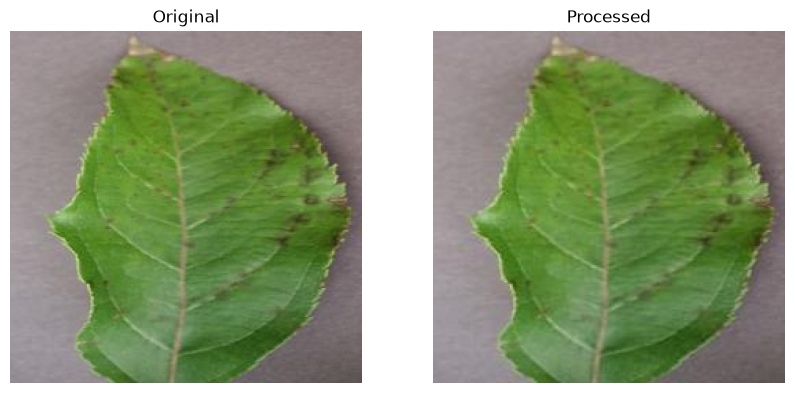

In [30]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(original)
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(processed)
plt.title("Processed")
plt.axis("off")

plt.show()

In [31]:
print("Original:", original.size)

print("Processed:", processed.size)

Original: (256, 256)
Processed: (224, 224)


In [32]:
print(original.mode)

print(processed.mode)

RGB
RGB


###Image Normalization

In [33]:
import numpy as np

In [34]:
img = Image.open(output_image)

img_array = np.array(img)

print(img_array.shape)

(224, 224, 3)


In [35]:
print("Minimum Pixel Value :", img_array.min())
print("Maximum Pixel Value :", img_array.max())

Minimum Pixel Value : 0
Maximum Pixel Value : 210


In [36]:
normalized_image = img_array / 255.0

In [37]:
print("Minimum :", normalized_image.min())
print("Maximum :", normalized_image.max())

Minimum : 0.0
Maximum : 0.8235294117647058


In [38]:
print(img_array.dtype)

print(normalized_image.dtype)

uint8
float64


In [39]:
print("Before Normalization:")
print(img_array[0, 0])

print()

print("After Normalization:")
print(normalized_image[0, 0])

Before Normalization:
[162 150 154]

After Normalization:
[0.63529412 0.58823529 0.60392157]


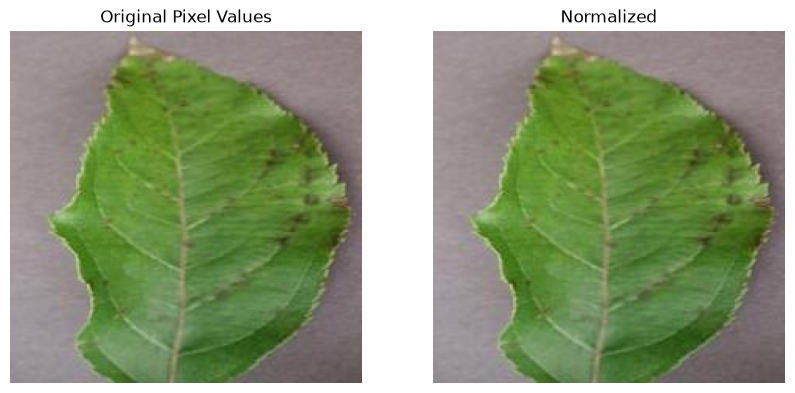

In [40]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img_array)
plt.title("Original Pixel Values")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(normalized_image)
plt.title("Normalized")
plt.axis("off")

plt.show()

##Data Augmentation

In [41]:
import tensorflow as tf

In [42]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10),
])

In [ ]:
sample = Image.open(sample_image)

sample = sample.resize((224,224))

sample = np.array(sample)

sample = np.expand_dims(sample, axis=0)

In [44]:
augmented = data_augmentation(sample)

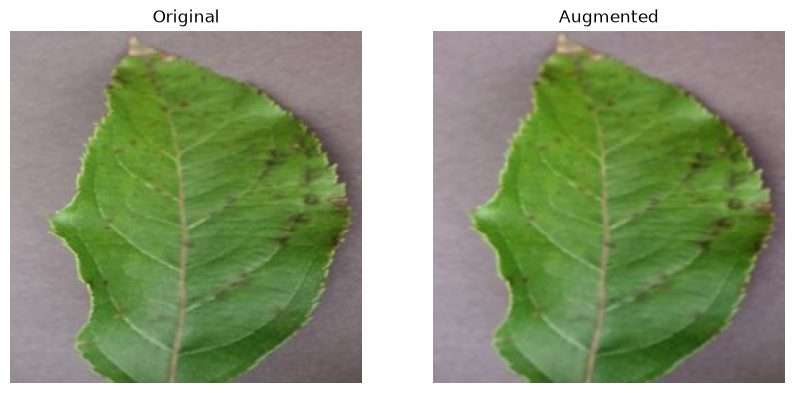

In [45]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(sample[0].astype("uint8"))
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(augmented[0].numpy().astype("uint8"))
plt.title("Augmented")
plt.axis("off")

plt.show()

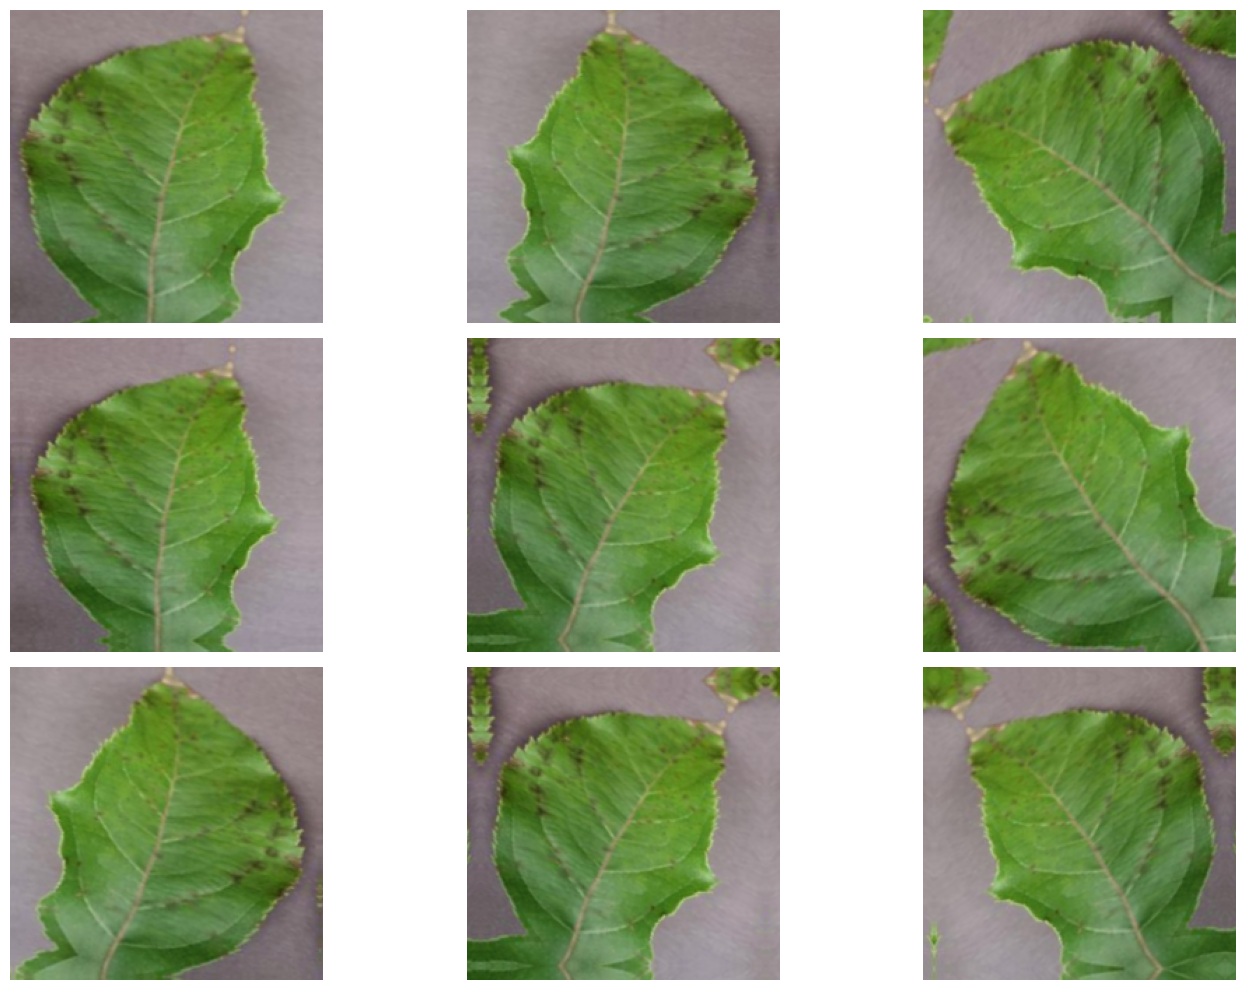

In [46]:
plt.figure(figsize=(15,10))

for i in range(9):

    augmented = data_augmentation(sample)

    plt.subplot(3,3,i+1)

    plt.imshow(augmented[0].numpy().astype("uint8"))

    plt.axis("off")

plt.tight_layout()

plt.show()

###Build the TensorFlow Data Pipeline

In [47]:
IMG_SIZE = (224, 224)

BATCH_SIZE = 32

SEED = 42

In [48]:
train_dir = TRAIN_PATH

val_dir = VAL_PATH

test_dir = TEST_PATH

In [49]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

Found 52141 files belonging to 38 classes.


In [50]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 10270 files belonging to 38 classes.


In [51]:
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 10352 files belonging to 38 classes.


In [52]:
class_names = train_dataset.class_names

print(class_names)

['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry___Powdery_mildew', 'Cherry___healthy', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___Northern_Leaf_Blight', 'Corn___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mos

In [53]:
print("Number of Classes:", len(class_names))

Number of Classes: 38


In [54]:
for images, labels in train_dataset.take(1):

    print(images.shape)

    print(labels.shape)

(32, 224, 224, 3)
(32,)


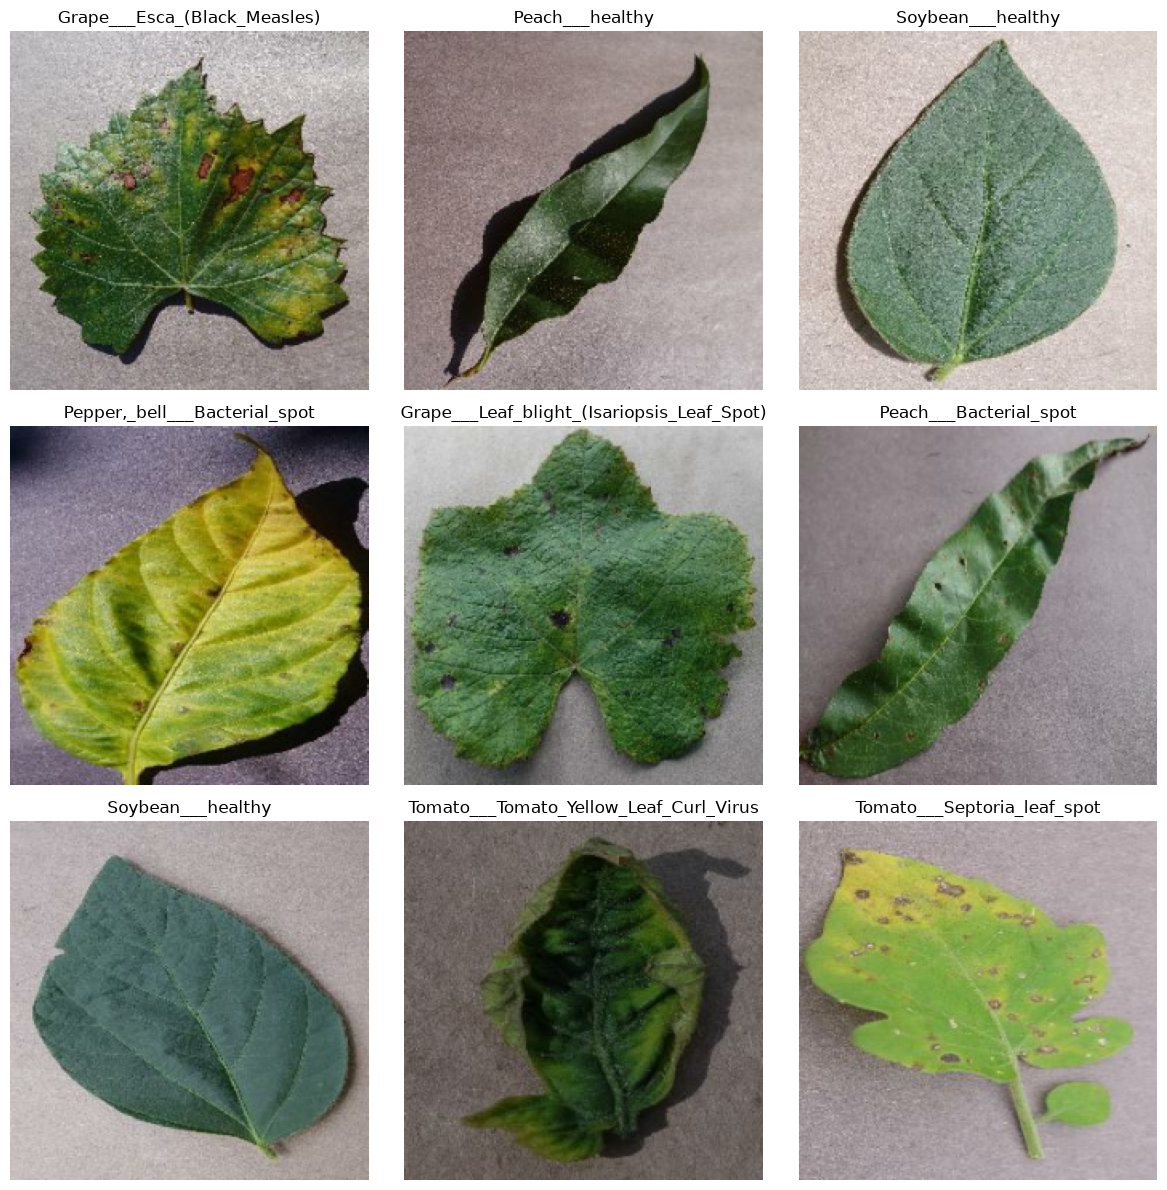

In [55]:
plt.figure(figsize=(12,12))

for images, labels in train_dataset.take(1):

    for i in range(9):

        plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

plt.tight_layout()

plt.show()

In [56]:
AUTOTUNE = tf.data.AUTOTUNE

In [57]:
train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)

validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

##Verify the Preprocessing Pipeline

In [58]:
print("Training batches   :", len(train_dataset))
print("Validation batches :", len(validation_dataset))
print("Testing batches    :", len(test_dataset))

Training batches   : 1630
Validation batches : 321
Testing batches    : 324


In [59]:
for images, labels in train_dataset.take(1):

    print("Image Batch Shape :", images.shape)

    print("Label Shape :", labels.shape)

Image Batch Shape : (32, 224, 224, 3)
Label Shape : (32,)


In [60]:
for images, labels in train_dataset.take(1):

    print(images.numpy().min())

    print(images.numpy().max())

0.0
254.2092


In [61]:
for images, labels in train_dataset.take(1):

    print(labels.numpy())

[24 22 28 26 13 34 24 30 24 32 24 32 12 26 12 33 35 37 29 15 30 24  3  4
 13 35 24 33 33 37 12 25]


In [62]:
print(class_names)

['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry___Powdery_mildew', 'Cherry___healthy', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___Northern_Leaf_Blight', 'Corn___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mos

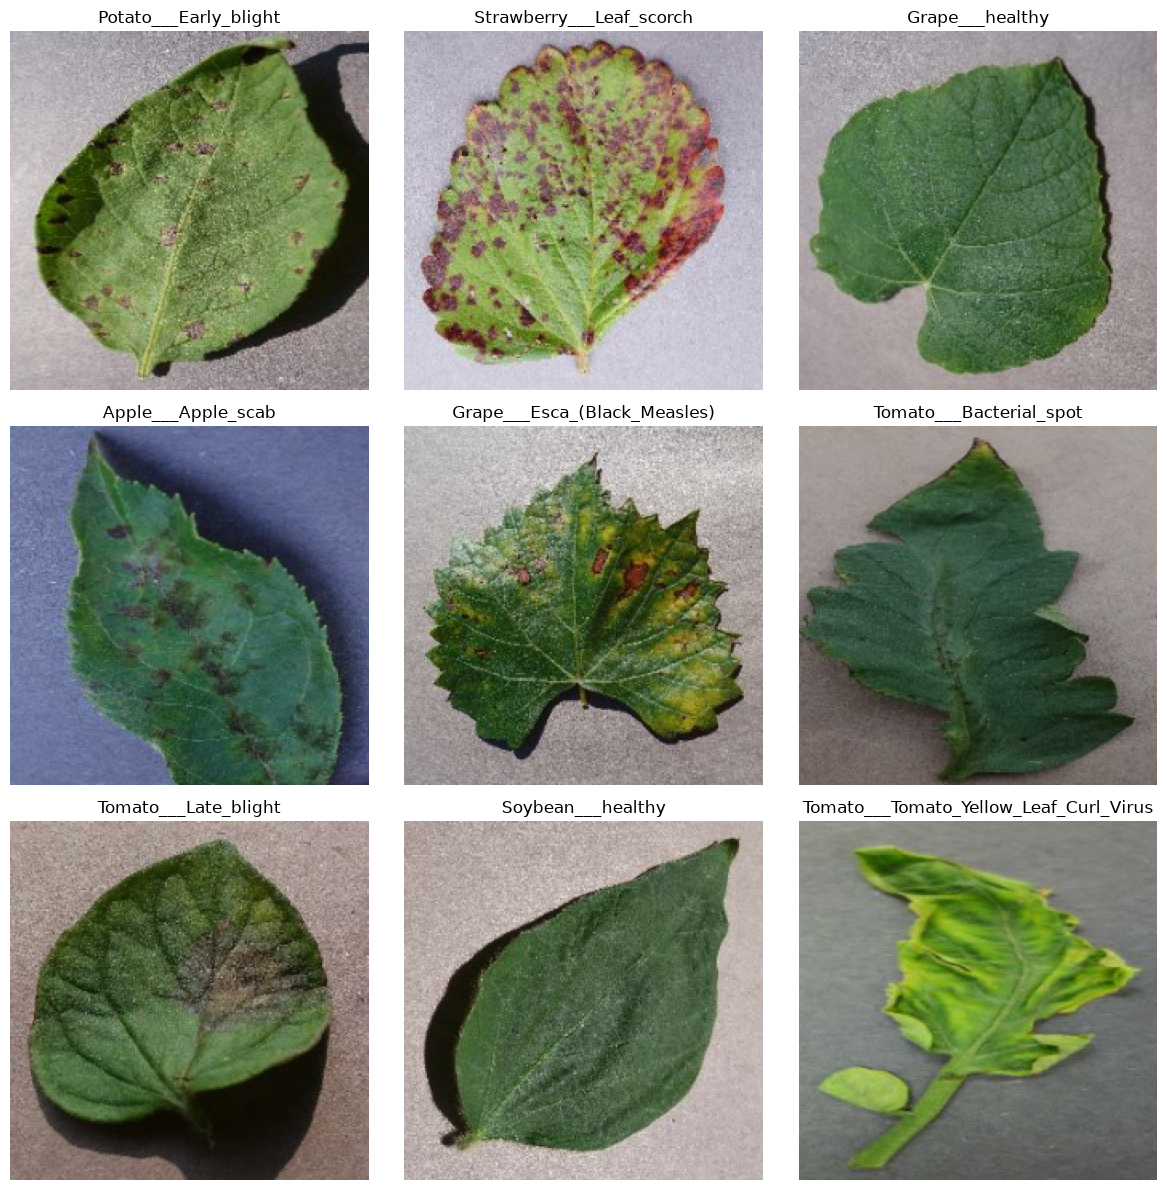

In [63]:
plt.figure(figsize=(12,12))

for images, labels in train_dataset.take(1):

    for i in range(9):

        plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

plt.tight_layout()

plt.show()

In [64]:
for images, labels in train_dataset.take(1):

    print(images[0].shape)

(224, 224, 3)


In [65]:
train_images = sum(1 for _ in TRAIN_PATH.rglob("*.*"))

val_images = sum(1 for _ in VAL_PATH.rglob("*.*"))

test_images = sum(1 for _ in TEST_PATH.rglob("*.*"))

print(train_images)

print(val_images)

print(test_images)

print(train_images+val_images+test_images)

52141
10270
10352
72763


In [66]:
summary = pd.DataFrame({

    "Dataset":[
        "Train",
        "Validation",
        "Test"
    ],

    "Images":[
        train_images,
        val_images,
        test_images
    ]

})

summary

,Dataset,Images
0,Train,52141
1,Validation,10270
2,Test,10352


In [67]:
summary.to_csv(
    "../reports/evaluation/dataset_summary.csv",
    index=False
)